# English movie-review sentiment classification with a bidirectional LSTM

    **Learning outcomes:** build a vocabulary from training data, encode and pad reviews,
    train an order-sensitive model, select a validation checkpoint, and predict English labels.

    This lesson uses IMDb movie reviews instead of Chinese hotel reviews. It uses an
    English tokenizer rather than Chinese word segmentation. Both framework editions
    share the same prepared data and label mapping, but have separate environments and outputs.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.15
torch: 2.14.1
Run mode: Default classroom training parameters


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
FRAMEWORK = "pytorch"
EXPERIMENT = "lstm-sentiment"

import json
import random
import numpy as np
from course_data import load_reviews, tokenize, build_vocab, encode, LABELS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
DATA = COURSE / "03-sentiment-analysis" / "data"
OUTPUT = COURSE / "03-sentiment-analysis" / "outputs" / FRAMEWORK / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
train_rows = load_reviews(DATA, "train", 64 if SMOKE else 4000)
validation_rows = load_reviews(DATA, "validation", 32 if SMOKE else 1000)
test_rows = load_reviews(DATA, "test", 32 if SMOKE else 1000)
print("Split sizes:", len(train_rows), len(validation_rows), len(test_rows))
print("Labels:", LABELS)

Split sizes: 4000 1000 1000
Labels: ['negative', 'positive']


## 1. Build a vocabulary without test leakage

    `<pad>` is ID 0; `<unk>` is ID 1. Truncate very long reviews for the classroom
    experiment and track true lengths. The vocabulary is fitted on training text only.
    Do not remove "not" or other negation words as stopwords.

In [4]:
MAX_LENGTH = 40 if SMOKE else 200
vocab = build_vocab([row["text"] for row in train_rows], max_words=20000)
(OUTPUT / "vocab.json").write_text(json.dumps(vocab, indent=2), encoding="utf-8")
ids, length = encode("The acting wasn't convincing, but I liked the music.", vocab, MAX_LENGTH)
print("Vocabulary size:", len(vocab), "True length:", length)
print("First token IDs:", ids[:12])
print("English label mapping:", dict(enumerate(LABELS)))

Vocabulary size: 20000 True length: 9
First token IDs: [2, 116, 264, 1070, 18, 10, 434, 2, 202, 0, 0, 0]
English label mapping: {0: 'negative', 1: 'positive'}


## 2. Define the model and training step

    Embedding maps IDs to vectors. A bidirectional LSTM summarizes the review in both
    directions. Concatenated final states feed a two-class linear layer. Sequence lengths
    are passed to the recurrent computation so padding does not contaminate final states.
    Gradient clipping limits unusually large updates.

In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence

torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def make_loader(rows, shuffle=False):
    encoded = [encode(row["text"], vocab, MAX_LENGTH) for row in rows]
    ids = torch.tensor([item[0] for item in encoded], dtype=torch.long)
    lengths = torch.tensor([item[1] for item in encoded], dtype=torch.long)
    labels = torch.tensor([row["label"] for row in rows], dtype=torch.long)
    return DataLoader(TensorDataset(ids, lengths, labels), batch_size=32,
                      shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, 2)

    def forward(self, ids, lengths):
        embedded = self.embedding(ids)
        # Ignore right-padding when computing the final states in both directions.
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                       enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(self.dropout(torch.cat([hidden[-2], hidden[-1]], dim=1)))

model = SentimentLSTM(len(vocab)).to(DEVICE)
train_loader = make_loader(train_rows, True)
validation_loader = make_loader(validation_rows)
test_loader = make_loader(test_rows)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(loader, training=False):
    model.train(training)
    loss_total, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for ids, lengths, labels in loader:
            ids, labels = ids.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            loss_total += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return loss_total / count, correct / count

def save_weights(path):
    torch.save(model.state_dict(), path)

def load_weights(path):
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))

def predict(texts):
    encoded = [encode(text, vocab, MAX_LENGTH) for text in texts]
    ids = torch.tensor([item[0] for item in encoded], device=DEVICE)
    lengths = torch.tensor([item[1] for item in encoded])
    model.eval()
    with torch.no_grad():
        return model(ids, lengths).softmax(1).cpu().numpy()

## 3. Train and select by validation accuracy

In [6]:
EPOCHS = 1 if SMOKE else 5
checkpoint = OUTPUT / ("best_model.pt" if FRAMEWORK == "pytorch" else "best_model.pdparams")
history, best_accuracy = [], -1.0
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(validation_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        save_weights(checkpoint)
    print(f"Epoch {epoch + 1}/{EPOCHS} | training loss {train_loss:.4f} | "
          f"validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.3f}")

Epoch 1/5 | training loss 0.6914 | validation loss 0.6829 | validation accuracy 0.574


Epoch 2/5 | training loss 0.6358 | validation loss 0.6225 | validation accuracy 0.665


Epoch 3/5 | training loss 0.5071 | validation loss 0.5863 | validation accuracy 0.695


Epoch 4/5 | training loss 0.3902 | validation loss 0.6189 | validation accuracy 0.715


Epoch 5/5 | training loss 0.2864 | validation loss 0.6578 | validation accuracy 0.724


## 4. Reload and evaluate on held-out test reviews

Test accuracy: 0.743; test loss: 0.6429


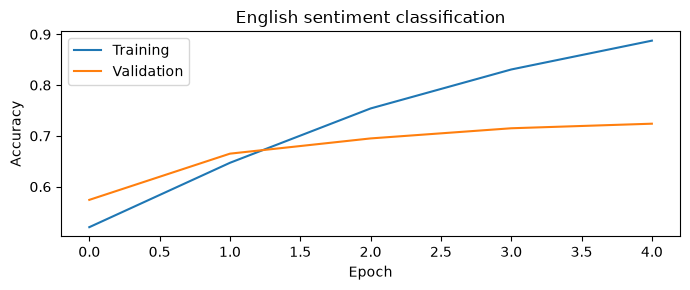

In [7]:
load_weights(checkpoint)
test_loss, test_accuracy = run_epoch(test_loader)
print(f"Test accuracy: {test_accuracy:.3f}; test loss: {test_loss:.4f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "max_length": MAX_LENGTH, "labels": LABELS,
           "split_sizes": [len(train_rows), len(validation_rows), len(test_rows)]}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
import matplotlib.pyplot as plt
values = np.asarray(history)
fig, axis = plt.subplots(figsize=(7, 3))
axis.plot(values[:, 2], label="Training")
axis.plot(values[:, 3], label="Validation")
axis.set(title="English sentiment classification", xlabel="Epoch", ylabel="Accuracy")
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "accuracy.png")
plt.show()

## 5. Predict new English reviews

In [8]:
reviews = ["The movie was wonderful and the acting was excellent.",
           "The plot was boring and the ending was disappointing.",
           "I expected to hate it, but it was not bad at all."]
probabilities = predict(reviews)
for text, scores in zip(reviews, probabilities):
    label = int(np.argmax(scores))
    print(f"{LABELS[label]} ({scores[label]:.3f}): {text}")

assert probabilities.shape == (len(reviews), 2)
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
# The same review should not change prediction because of other batch members.
assert np.allclose(predict([reviews[0]])[0], probabilities[0], atol=1e-5)
print("Predictions can be wrong, especially after a short classroom run.")

positive (0.767): The movie was wonderful and the acting was excellent.
negative (0.851): The plot was boring and the ending was disappointing.
negative (0.987): I expected to hate it, but it was not bad at all.
Predictions can be wrong, especially after a short classroom run.


## Exercises

    Compare a unidirectional and bidirectional model. Change the maximum length and
    measure truncation frequency. Inspect negation and mixed reviews. Keep all tuning
    on the validation set. To reproduce predictions later, restore the vocabulary,
    maximum length, architecture, class mapping, and weights together.

    For an already fine-tuned English transformer, use the optional pretrained-model
    lesson in the PyTorch route. Its SST-2 training task differs from this IMDb experiment;
    its published scores are not this course's results.